In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (r2_score, mean_squared_error,
                             mean_absolute_error, mean_absolute_percentage_error, 
                             root_mean_squared_error, explained_variance_score) 
from sklearn.preprocessing import PolynomialFeatures
import seaborn as sns

In [2]:
plt.rcParams['font.size'] = 15

In [3]:
features = ['Obs', 'Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height%', 'Width%', 'Sex']
data = pd.read_csv('fishcatch.dat.txt', header=None, delimiter=r'[ \t]+', engine='python', names=features)
data.head()

,Obs,Species,Weight,Length1,Length2,Length3,Height%,Width%,Sex
0,1,1,242.0,23.2,25.4,30.0,38.4,13.4,NaN
1,2,1,290.0,24.0,26.3,31.2,40.0,13.8,NaN
2,3,1,340.0,23.9,26.5,31.1,39.8,15.1,NaN
3,4,1,363.0,26.3,29.0,33.5,38.0,13.3,NaN
4,5,1,430.0,26.5,29.0,34.0,36.6,15.1,NaN


In [4]:
np.unique_counts(data.Species)

UniqueCountsResult(values=array([1, 2, 3, 4, 5, 6, 7]), counts=array([35,  6, 20, 11, 14, 17, 56]))

In [5]:
data[data.Species == 7].info()

<class 'pandas.DataFrame'>
RangeIndex: 56 entries, 103 to 158
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Obs      56 non-null     int64  
 1   Species  56 non-null     int64  
 2   Weight   56 non-null     float64
 3   Length1  56 non-null     float64
 4   Length2  56 non-null     float64
 5   Length3  56 non-null     float64
 6   Height%  56 non-null     float64
 7   Width%   56 non-null     float64
 8   Sex      27 non-null     float64
dtypes: float64(7), int64(2)
memory usage: 4.1 KB


In [6]:
df = data.loc[data.Species == 7, ['Length3', 'Weight']]
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56 entries, 103 to 158
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Length3  56 non-null     float64
 1   Weight   56 non-null     float64
dtypes: float64(2)
memory usage: 1.0 KB


In [7]:
df.head()

,Length3,Weight
103,8.8,5.9
104,14.7,32.0
105,16.0,40.0
106,17.2,51.5
107,18.5,70.0


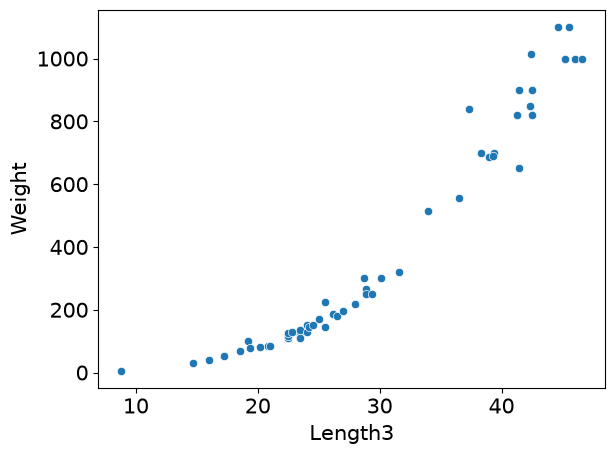

In [8]:
sns.scatterplot(data=df, x='Length3', y='Weight')
plt.tight_layout()

In [9]:
X = df.iloc[:,:1]
y = df.iloc[:,1]

In [10]:
model = LinearRegression().fit(X, y)

In [11]:
(w := model.coef_, b := model.intercept_)

(array([35.00089353]), np.float64(-652.7871372535784))

ycoord = array([-302.77820195, 1097.25753926])
0    -302.778202
1    1097.257539
Name: Length3, dtype: float64


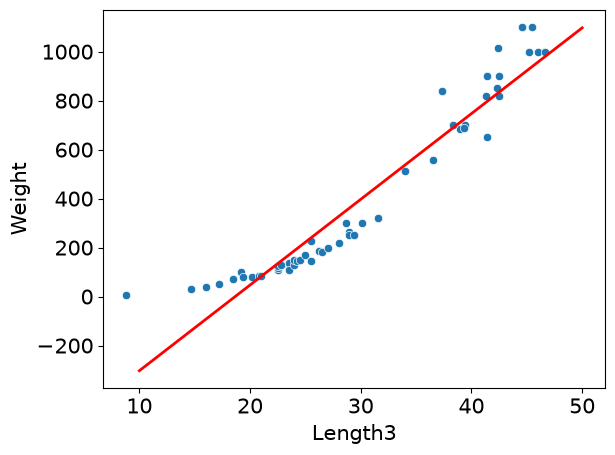

In [12]:
sns.scatterplot(data=df, x='Length3', y='Weight')
xcoord = pd.DataFrame(np.array([[10.], [50.]]), columns=['Length3'])
ycoord = model.predict(xcoord)

print(f'{ycoord = }')
print(f'{w*xcoord.Length3 + b}')

sns.lineplot(x=xcoord.Length3, y=ycoord, color='r', lw=2)
plt.tight_layout()

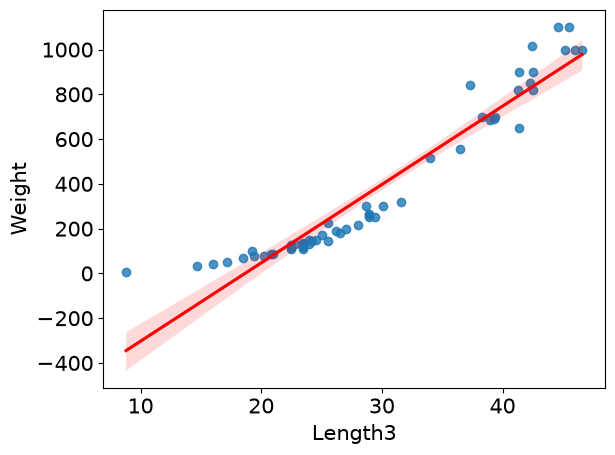

In [13]:
sns.regplot(data=df, x='Length3', y='Weight', line_kws={'color': 'r'})
plt.tight_layout()

y.mean() = 382.239286
y_pred.mean() = 382.239286
res.mean() = 0.000000


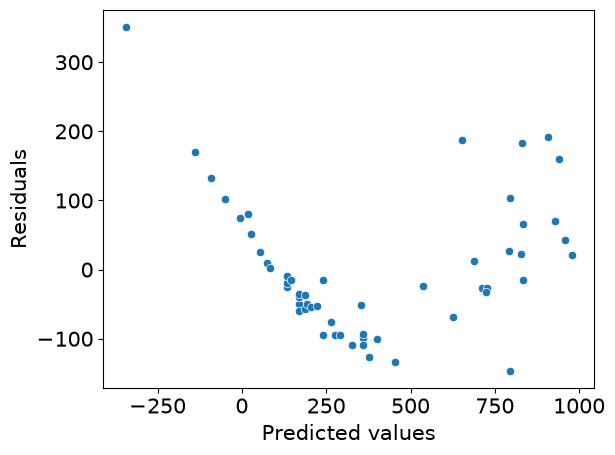

In [14]:
y_pred = model.predict(X)
sns.scatterplot(x=y_pred, y=(res:=y-y_pred))
plt.xlabel('Predicted values')
plt.ylabel('Residuals')
print(f'{y.mean() = :f}')
print(f'{y_pred.mean() = :f}')
print(f'{res.mean() = :f}')
plt.tight_layout()

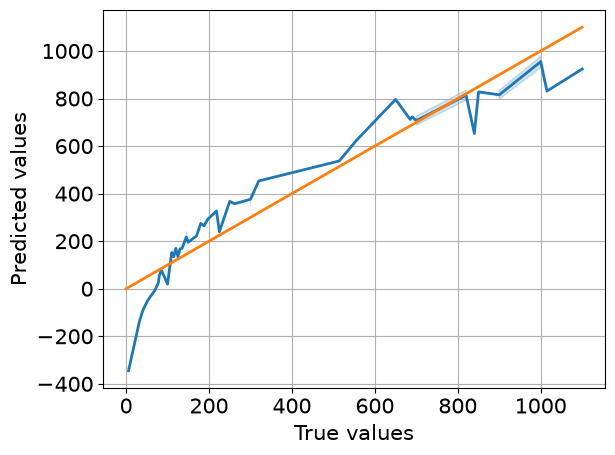

In [15]:
sns.lineplot(x=y, y=y_pred, lw=2)
plt.xlabel('True values')
plt.ylabel('Predicted values')
sns.lineplot(x=[0, y.max()], y=[0, y.max()], lw=2)
plt.grid()
plt.tight_layout()

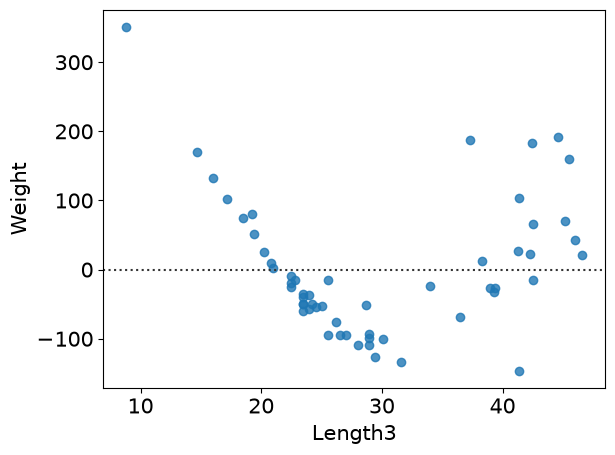

In [16]:
sns.residplot(data=df, x='Length3', y='Weight')
plt.tight_layout()

In [17]:
r = np.corrcoef(X.Length3, y)[0, 1]
print(f'{r = :f}')

r = 0.959506


$$\tilde{y} = \omega x + b $$
$$\hat{x} = \frac{x - \overline{x}}{\sigma_x},\qquad 
\hat{y} = \frac{\tilde{y} - \overline{y}}{\sigma_y}$$
$$\hat{y} = r\hat{x}$$
$$ r = \frac{\omega \sigma_x}{\sigma_y},\qquad 
b =  \overline{y} - \omega \overline{x}$$

In [18]:
w*X.Length3.std()/y.std()

array([0.95950608])

In [19]:
b, y.mean() - w*X.Length3.mean()

(np.float64(-652.7871372535784), array([-652.78713725]))

$$MSE = \frac{1}{N} \sum\limits_{i=1}^N {\left(y^{(i)} - \boldsymbol{\omega}^T \textbf{x}^{(i)} - b \right)}^2$$
$$RMSE = \sqrt{MSE}$$

In [20]:
mse = ((y - w*X.Length3 - b)**2).mean()
rmse = np.sqrt(mse)
print(f'{mse = :f}')
print(f'{rmse = :f}')

mse = 9417.050885
rmse = 97.041491


In [21]:
print(f'MSE = {mean_squared_error(y_true=y, y_pred=y_pred):f}')
print(f'RMSE = {root_mean_squared_error(y_true=y, y_pred=y_pred):f}')

MSE = 9417.050885
RMSE = 97.041491


$$RMSE(\textbf{x}, \textbf{y}) = \sigma_y \sqrt{1-r^2}$$
$$RMSE(\hat{\textbf{x}}, \hat{\textbf{y}}) = \sqrt{1-r^2}$$

In [22]:
sy = y.std(ddof=0)
root_mean_squared_error(y_true=y, y_pred=y_pred), sy*np.sqrt(1-r**2)

(97.04149053587213, np.float64(97.04149053587214))

$$MAE = \frac{1}{N} \sum\limits_{i=1}^N {\left| y^{(i)} - \boldsymbol{\omega}^T \textbf{x}^{(i)} - b \right|}$$
$$MAPE = \frac{1}{N} \sum\limits_{i=1}^N {\left| \frac{y^{(i)} - \boldsymbol{\omega}^T \textbf{x}^{(i)} - b}
{y^{(i)}} \right|}$$

In [23]:
mae = np.abs(y - w*X.Length3 - b).mean()
mape = np.abs((y - w*X.Length3 - b)/y).mean()
print(f'{mae = :.2f}')
print(f'{mape = :.2f}')

mae = 74.68
mape = 1.50


In [24]:
print(f'MAE = {mean_absolute_error(y_true=y, y_pred=y_pred):.2f}')
print(f'MAPE = {mean_absolute_percentage_error(y_true=y, y_pred=y_pred):.2f}')
print(f'MAPE = {100*mean_absolute_percentage_error(y_true=y, y_pred=y_pred):.2f}%')

MAE = 74.68
MAPE = 1.50
MAPE = 150.36%


In [25]:
print(f'MAPE(y>20) = {100*mean_absolute_percentage_error(
    y_true=y[y>20], y_pred=y_pred[y>20]):.2f}%')

MAPE(y>20) = 45.02%


$$\tilde{\textbf{y}} = X\boldsymbol{\omega}^T+b$$
$$R^2 = 1 - \frac{\sum\limits_{i=1}^N \left(\tilde{y}^{(i)}-y^{(i)}\right)^2}
{\sum\limits_{i=1}^N \left(y^{(i)} - \overline{y} \right)^2}=
1-\frac{MSE}{\text{var}(\textbf{y})}$$
Для линейной регрессии:
$$R^2 = \frac{\text{var}(X\boldsymbol{\omega}^T+b)}{\text{var}(\textbf{y})}$$

In [26]:
y_pred.var(ddof=0)/y.var(ddof=0), 1. - mse/y.var(ddof=0), r**2

(np.float64(0.9206519153260058),
 np.float64(0.920651915326006),
 np.float64(0.920651915326006))

In [27]:
print(f'R² = {r2_score(y_true=y, y_pred=y_pred):f}')

R² = 0.920652


$$EV = 1-\frac{\text{var}(\textbf{y}-\tilde{\textbf{y}})}{\text{var}(\textbf{y})}$$
Если $\overline{(\textbf{y}-\tilde{\textbf{y}})} = 0$:
$$EV=R^2$$

In [28]:
print(f'EV = {explained_variance_score(y_true=y, y_pred=y_pred):f}')

EV = 0.920652


In [29]:
X3 = PolynomialFeatures(degree=3, include_bias=False).fit_transform(X)
print(X3[:10])

[[8.800000e+00 7.744000e+01 6.814720e+02]
 [1.470000e+01 2.160900e+02 3.176523e+03]
 [1.600000e+01 2.560000e+02 4.096000e+03]
 [1.720000e+01 2.958400e+02 5.088448e+03]
 [1.850000e+01 3.422500e+02 6.331625e+03]
 [1.920000e+01 3.686400e+02 7.077888e+03]
 [1.940000e+01 3.763600e+02 7.301384e+03]
 [2.020000e+01 4.080400e+02 8.242408e+03]
 [2.080000e+01 4.326400e+02 8.998912e+03]
 [2.100000e+01 4.410000e+02 9.261000e+03]]


In [30]:
cubic_model = LinearRegression().fit(X3, y) # fit_intercept=False

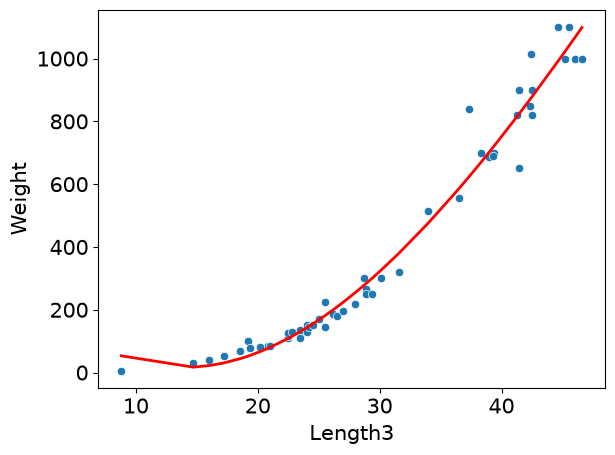

In [31]:
sns.scatterplot(x=X.Length3, y=y)
y_pred = cubic_model.predict(X3)
sns.lineplot(x=X.Length3, y=y_pred, color='red', lw=2)
plt.tight_layout()

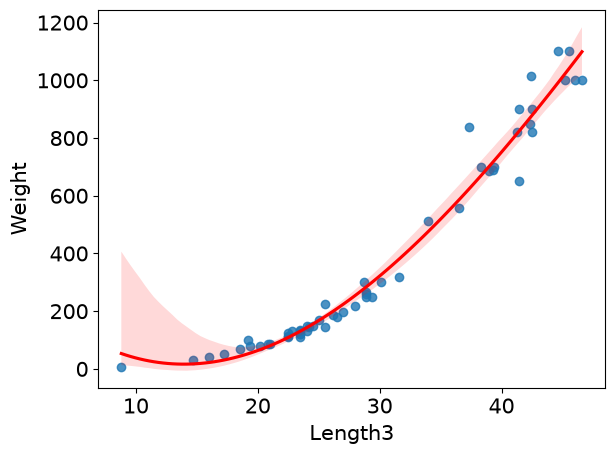

In [32]:
sns.regplot(data=df, x='Length3', y='Weight', line_kws={'color': 'r'}, order=3)
plt.tight_layout()

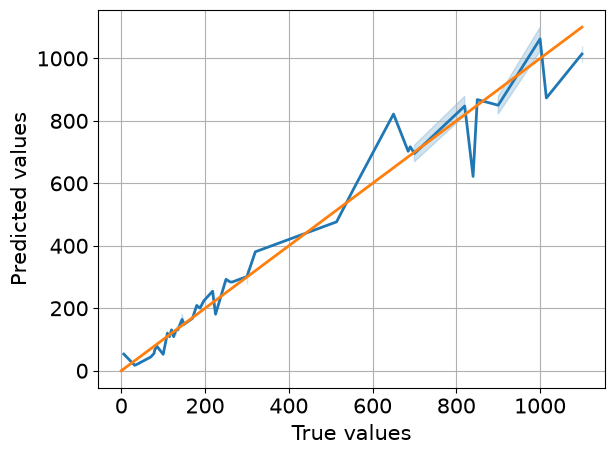

In [33]:
sns.lineplot(x=y, y=y_pred, lw=2)
plt.xlabel('True values')
plt.ylabel('Predicted values')
sns.lineplot(x=[0, y.max()], y=[0, y.max()], lw=2)
plt.grid()
plt.tight_layout()

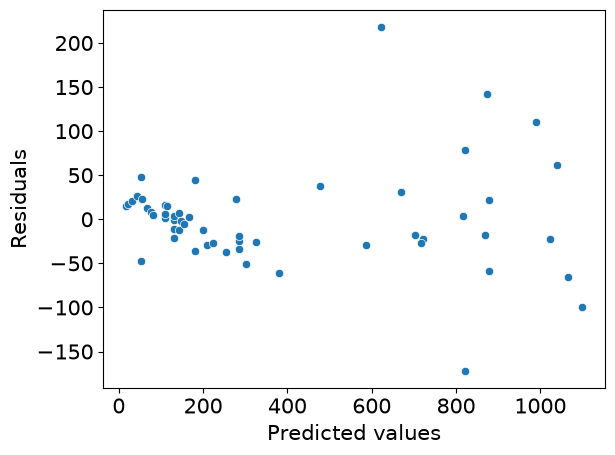

In [34]:
sns.scatterplot(x=y_pred, y=y-y_pred)
plt.xlabel('Predicted values')
plt.ylabel('Residuals')
plt.tight_layout()

In [35]:
print(f'R² = {r2_score(y_true=y, y_pred=y_pred):f}')
print(f'MAPE = {100*mean_absolute_percentage_error(y_true=y, y_pred=y_pred):.2f}%')
print(f'RMSE = {root_mean_squared_error(y_true=y, y_pred=y_pred):f}')

R² = 0.974863
MAPE = 26.84%
RMSE = 54.619572
